In [1]:
from pathlib import Path
import sys
import tensorflow as tf

print("Python:", sys.executable)
print("Carpeta actual:", Path.cwd())
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print(
    "Anotaciones encontradas:",
    Path("../PROJECT/xview_recognition/xview_ann_train.json").is_file()
)

I0000 00:00:1792178336.904043  200421 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Python: /home/pablo/venvs/muia-cv/bin/python
Carpeta actual: /home/pablo/muia-cv-project/PROJECT/experiments/fnn_challenge/experiment_13
TensorFlow: 2.21.0
GPU: []
Anotaciones encontradas: False


W0000 00:00:1792178339.901163  200421 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [2]:
from pathlib import Path
import os

PROJECT_DIR = Path("/home/pablo/muia-cv-project/PROJECT")

# Mantener el directorio de trabajo que utilizábamos antes.
os.chdir(PROJECT_DIR)

EXPERIMENT_DIR = PROJECT_DIR / "experiments" / "fnn_challenge" / "experiment_12"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = EXPERIMENT_DIR / "model.keras"
PREDICTION_PATH = EXPERIMENT_DIR / "prediction.json"

print("Carpeta de trabajo:", Path.cwd())
print("Resultados:", EXPERIMENT_DIR)
print(
    "Anotaciones encontradas:",
    (PROJECT_DIR / "xview_recognition" / "xview_ann_train.json").is_file()
)

Carpeta de trabajo: /home/pablo/muia-cv-project/PROJECT
Resultados: /home/pablo/muia-cv-project/PROJECT/experiments/fnn_challenge/experiment_12
Anotaciones encontradas: True


## Assignment: Image recognition
- Alumno 1:
- Alumno 2:
- Alumno 3:

The goals of the assignment are:
* Develop proficiency in using Tensorflow/Keras for training Neural Nets (NNs).
* Put into practice the acquired knowledge to optimize the parameters and architecture of a feedforward Neural Net (ffNN), in the context of an image recognition problem.
* Put into practice NNs specially conceived for analysing images. Design and optimize the parameters of a Convolutional Neural Net (CNN) to deal with previous task.
* Train popular architectures from scratch (e.g., GoogLeNet, VGG, ResNet, ...), and compare the results with the ones provided by their pre-trained versions using transfer learning.

Follow the link below to download the classification data set  “xview_recognition”: [https://drive.upm.es/s/2DDPE2zHw5dbM3G](https://drive.upm.es/s/2DDPE2zHw5dbM3G)

In [3]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[]


In [4]:
import uuid
import numpy as np

class GenericObject:
    """
    Generic object data.
    """
    def __init__(self):
        self.id = uuid.uuid4()
        self.bb = (-1, -1, -1, -1)
        self.category= -1
        self.score = -1

class GenericImage:
    """
    Generic image data.
    """
    def __init__(self, filename):
        self.filename = filename
        self.tile = np.array([-1, -1, -1, -1])  # (pt_x, pt_y, pt_x+width, pt_y+height)
        self.objects = list([])

    def add_object(self, obj: GenericObject):
        self.objects.append(obj)

In [5]:
categories = {0: 'Cargo plane', 1: 'Small car', 2: 'Bus', 3: 'Truck', 4: 'Motorboat', 5: 'Fishing vessel', 6: 'Dump truck', 7: 'Excavator', 8: 'Building', 9: 'Helipad', 10: 'Storage tank', 11: 'Shipping container', 12: 'Pylon'}

In [6]:
# CAMBIO: Entrada RGB de 32 × 32, normalizada a [0, 1]; lectura de bandas conjunta y cierre del archivo.
# Código original conservado como comentarios:
# import warnings
# import rasterio
# import numpy as np
#
# def load_geoimage(filename):
#     warnings.filterwarnings('ignore', category=rasterio.errors.NotGeoreferencedWarning)
#     src_raster = rasterio.open('../PROJECT/xview_recognition/'+filename, 'r')
#     # RasterIO to OpenCV (see inconsistencies between libjpeg and libjpeg-turbo)
#     input_type = src_raster.profile['dtype']
#     input_channels = src_raster.count
#     img = np.zeros((src_raster.height, src_raster.width, src_raster.count), dtype=input_type)
#     for band in range(input_channels):
#         img[:, :, band] = src_raster.read(band+1)
#     return img

# Código actualizado:
import warnings
import rasterio
from rasterio.enums import Resampling
import numpy as np

IMAGE_SIZE = (32, 32)  # (alto, ancho); tamaño original: 224 × 224.
IMAGE_CHANNELS = 3

def load_geoimage(filename):
    # Leer directamente al tamaño final evita almacenar imágenes de 224 × 224.
    # Promediar los píxeles al reducir ayuda a evitar aliasing.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
        with rasterio.open(PROJECT_DIR / "xview_recognition" / filename, "r") as src_raster:
            if src_raster.count != IMAGE_CHANNELS or any(dtype != 'uint8' for dtype in src_raster.dtypes):
                raise ValueError(f'Se esperaba una imagen RGB uint8: {filename}')
            bands = src_raster.read(
                out_shape=(IMAGE_CHANNELS, *IMAGE_SIZE),
                resampling=Resampling.average,
                out_dtype='float32',
            )
    return np.moveaxis(bands, 0, -1) / np.float32(255.0)


#### Training
Design and train a ffNN to deal with the “xview_recognition” classification task.

In [7]:
import json

json_file = PROJECT_DIR / "xview_recognition" / "xview_ann_train.json"

with open(json_file) as ifs:
    json_data = json.load(ifs)

In [8]:
import numpy as np

counts = dict.fromkeys(categories.values(), 0)
anns = []
for json_img, json_ann in zip(json_data['images'].values(), json_data['annotations'].values()):
    image = GenericImage(json_img['filename'])
    image.tile = np.array([0, 0, json_img['width'], json_img['height']])
    obj = GenericObject()
    obj.bb = (int(json_ann['bbox'][0]), int(json_ann['bbox'][1]), int(json_ann['bbox'][2]), int(json_ann['bbox'][3]))
    obj.category = json_ann['category_id']
    # Resampling strategy to reduce training time
    counts[obj.category] += 1
    image.add_object(obj)
    anns.append(image)
print(counts)

{'Cargo plane': 635, 'Small car': 3324, 'Bus': 1768, 'Truck': 2210, 'Motorboat': 1069, 'Fishing vessel': 706, 'Dump truck': 1236, 'Excavator': 789, 'Building': 3594, 'Helipad': 111, 'Storage tank': 1469, 'Shipping container': 1523, 'Pylon': 312}


In [9]:
from sklearn.model_selection import train_test_split

anns_train, anns_valid = train_test_split(anns, test_size=0.1, random_state=1, shuffle=True)
print('Number of training images: ' + str(len(anns_train)))
print('Number of validation images: ' + str(len(anns_valid)))

Number of training images: 16871
Number of validation images: 1875


In [10]:
# CAMBIO: Entrada 32 × 32 × 3 y capas densas ocultas de 256, 128 y 64 neuronas con ReLU.
# Código original conservado como comentarios:
# # Load architecture
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Dense, Activation, Flatten
#
# print('Load model')
# model = Sequential()
# model.add(Flatten(input_shape=(224, 224, 3)))
# model.add(Activation('relu'))
# model.add(Dense(len(categories)))
# model.add(Activation('softmax'))
# model.summary()

# Código actualizado:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Activation, Flatten

print('Load model')
model = Sequential()
model.add(Input(shape=(*IMAGE_SIZE, IMAGE_CHANNELS)))
model.add(Flatten())
# CAMBIO: añadir tres capas densas ocultas para aprender relaciones no lineales.
# La activación anterior sobre los píxeles normalizados era redundante:
# model.add(Activation('relu'))
model.add(Dense(512, activation='relu'))
model.add(Dense(256, activation='relu'))
model.add(Dense(128, activation='relu'))
# CAMBIO: tercera capa densa oculta de 64 neuronas con ReLU.
# Conexión anterior conservada como comentario:
# model.add(Dense(len(categories)))
model.add(Dense(64, activation='relu'))
model.add(Dense(len(categories)))
model.add(Activation('softmax'))
model.summary()


Load model


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 13)             │           845 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 13)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,746,701 (6.66 MB)

 Trainable params: 1,746,701 (6.66 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# CAMBIO: SGD con learning_rate=3e-4, momentum=0.9, Nesterov y clipnorm=1.0.
# Configuración anterior: sustituir Adam por SGD con learning_rate=0.001 y clipnorm=1.0.
# from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import SGD

# Learning rate is changed to 0.001
# opt = Adam(learning_rate=1e-3, beta_1=0.9, beta_2=0.999, epsilon=1e-8, amsgrad=True, clipnorm=1.0)
# opt = SGD(learning_rate=1e-3, clipnorm=1.0)
# CAMBIO: activar momentum y Nesterov; reducir LR a 3 × 10^-4.
opt = SGD(
    learning_rate=1e-3,
    momentum=0.9,
    nesterov=True,
    clipnorm=1.0,
)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

In [12]:
from tensorflow.keras.callbacks import TerminateOnNaN, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Callbacks
model_checkpoint = ModelCheckpoint(
    str(MODEL_PATH),
    monitor="val_accuracy",
    mode="max",
    verbose=1,
    save_best_only=True,
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_accuracy",
    mode="max",
    factor=0.5,
    patience=10,
    verbose=1,
)
early_stop = EarlyStopping('val_accuracy', patience=40, verbose=1)
terminate = TerminateOnNaN()
callbacks = [model_checkpoint, reduce_lr, early_stop, terminate]

In [13]:
# CAMBIO: Sustituir el generador que releía archivos en cada época por una carga única en memoria.
# Código original conservado como comentarios:
# def generator_images(objs, batch_size, do_shuffle=False):
#     while True:
#         if do_shuffle:
#             np.random.shuffle(objs)
#         groups = [objs[i:i+batch_size] for i in range(0, len(objs), batch_size)]
#         for group in groups:
#             images, labels = [], []
#             for (filename, obj) in group:
#                 # Load image
#                 images.append(load_geoimage(filename))
#                 probabilities = np.zeros(len(categories))
#                 probabilities[list(categories.values()).index(obj.category)] = 1
#                 labels.append(probabilities)
#             images = np.array(images).astype(np.float32)
#             labels = np.array(labels).astype(np.float32)
#             yield images, labels

# Código actualizado:
category_names = list(categories.values())
category_to_index = {name: index for index, name in enumerate(category_names)}

def prepare_images(objs):
    # Reservar solo el tamaño final; no acumular las imágenes originales.
    images = np.empty((len(objs), *IMAGE_SIZE, IMAGE_CHANNELS), dtype=np.float32)
    labels = np.zeros((len(objs), len(categories)), dtype=np.float32)
    for index, (filename, obj) in enumerate(objs):
        images[index] = load_geoimage(filename)
        labels[index, category_to_index[obj.category]] = 1.0
    return images, labels


In [14]:
# CAMBIO: Precargar entrenamiento y validación una vez; fit reutilizará estos arrays en todas las épocas.
# Código original conservado como comentarios:
# # Generate the list of objects from annotations
# objs_train = [(ann.filename, obj) for ann in anns_train for obj in ann.objects]
# objs_valid = [(ann.filename, obj) for ann in anns_valid for obj in ann.objects]
# # Generators
# batch_size = 8
# train_generator = generator_images(objs_train, batch_size, do_shuffle=True)
# valid_generator = generator_images(objs_valid, batch_size, do_shuffle=False)

# Código actualizado:
objs_train = [(ann.filename, obj) for ann in anns_train for obj in ann.objects]
objs_valid = [(ann.filename, obj) for ann in anns_valid for obj in ann.objects]
batch_size = 8

x_train, y_train = prepare_images(objs_train)
x_valid, y_valid = prepare_images(objs_valid)
print(f'Entrenamiento: {x_train.shape}, rango [{x_train.min():.3f}, {x_train.max():.3f}]')
print(f'Validación: {x_valid.shape}, rango [{x_valid.min():.3f}, {x_valid.max():.3f}]')
print(f'Imágenes en memoria: {(x_train.nbytes + x_valid.nbytes) / 1024**2:.1f} MiB')


Entrenamiento: (16871, 32, 32, 3), rango [0.000, 1.000]
Validación: (1875, 32, 32, 3), rango [0.000, 1.000]
Imágenes en memoria: 219.7 MiB


In [15]:
# CAMBIO: Entrenar con arrays precargados, sin lecturas de imágenes durante las épocas; barajar solo entrenamiento.
# Código original conservado como comentarios:
# import math
# import numpy as np
#
# print('Training model')
# epochs = 20
# train_steps = math.ceil(len(objs_train)/batch_size)
# valid_steps = math.ceil(len(objs_valid)/batch_size)
# h = model.fit(train_generator, steps_per_epoch=train_steps, validation_data=valid_generator, validation_steps=valid_steps, epochs=epochs, callbacks=callbacks, verbose=1)
# # Best validation model
# best_idx = int(np.argmax(h.history['val_accuracy']))
# best_value = np.max(h.history['val_accuracy'])
# print('Best validation model: epoch ' + str(best_idx+1), ' - val_accuracy ' + str(best_value))

# Código actualizado:
import numpy as np

print('Training model')
epochs = 100
h = model.fit(
    x_train, y_train,
    batch_size=batch_size,
    validation_data=(x_valid, y_valid),
    shuffle=True,
    epochs=epochs,
    callbacks=callbacks,
    verbose=1,
)
# Best validation model
best_idx = int(np.argmax(h.history['val_accuracy']))
best_value = np.max(h.history['val_accuracy'])
print('Best validation model: epoch ' + str(best_idx + 1) + ' - val_accuracy ' + str(best_value))


Training model
Epoch 1/100
2104/2109 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3243 - loss: 2.0405
Epoch 1: val_accuracy improved from None to 0.39253, saving model to /home/pablo/muia-cv-project/PROJECT/experiments/fnn_challenge/experiment_12/model.keras

Epoch 1: finished saving model to /home/pablo/muia-cv-project/PROJECT/experiments/fnn_challenge/experiment_12/model.keras
2109/2109 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.3245 - loss: 2.0398 - val_accuracy: 0.3925 - val_loss: 1.8105 - learning_rate: 0.0010
Epoch 2/100
2103/2109 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4135 - loss: 1.7039
Epoch 2: val_accuracy improved from 0.39253 to 0.44160, saving model to /home/pablo/muia-cv-project/PROJECT/experiments/fnn_challenge/experiment_12/model.keras

Epoch 2: finished saving model to /home/pablo/muia-cv-project/PROJECT/experiments/fnn_challenge/experiment_12/model.keras
2109/2109 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.4135 - loss: 1.7032 - val_accuracy: 0.4416

#### Validation
Compute validation metrics.

In [16]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

def draw_confusion_matrix(cm, categories):
    # Draw confusion matrix
    fig = plt.figure(figsize=[6.4*pow(len(categories), 0.5), 4.8*pow(len(categories), 0.5)])
    ax = fig.add_subplot(111)
    cm = cm.astype('float') / np.maximum(cm.sum(axis=1)[:, np.newaxis], np.finfo(np.float64).eps)
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.colormaps['Blues'])
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]), xticklabels=list(categories.values()), yticklabels=list(categories.values()), ylabel='Annotation', xlabel='Prediction')
    # Rotate the tick labels and set their alignment
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    # Loop over data dimensions and create text annotations
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], '.2f'), ha="center", va="center", color="white" if cm[i, j] > thresh else "black", fontsize=int(20-pow(len(categories), 0.5)))
    fig.tight_layout()
    plt.show()

In [17]:
# CAMBIO: Reutilizar la validación precargada y predecir por lotes; sin releer archivos ni predecir imagen por imagen.
# Código original conservado como comentarios:
# import numpy as np
#
# model.load_weights('model.keras')
# y_true, y_pred = [], []
# for ann in anns_valid:
#     # Load image
#     image = load_geoimage(ann.filename)
#     for obj_pred in ann.objects:
#         # Generate prediction
#         warped_image = np.expand_dims(image, 0)
#         predictions = model.predict(warped_image, verbose=0)
#         # Save prediction
#         pred_category = list(categories.values())[np.argmax(predictions)]
#         pred_score = np.max(predictions)
#         y_true.append(obj_pred.category)
#         y_pred.append(pred_category)

# Código actualizado:
import numpy as np

# Usar el checkpoint generado por el nuevo entrenamiento a 32 × 32.
model.load_weights(str(MODEL_PATH))
valid_predictions = model.predict(x_valid, batch_size=batch_size, verbose=0)
y_true = [category_names[index] for index in np.argmax(y_valid, axis=1)]
y_pred = [category_names[index] for index in np.argmax(valid_predictions, axis=1)]


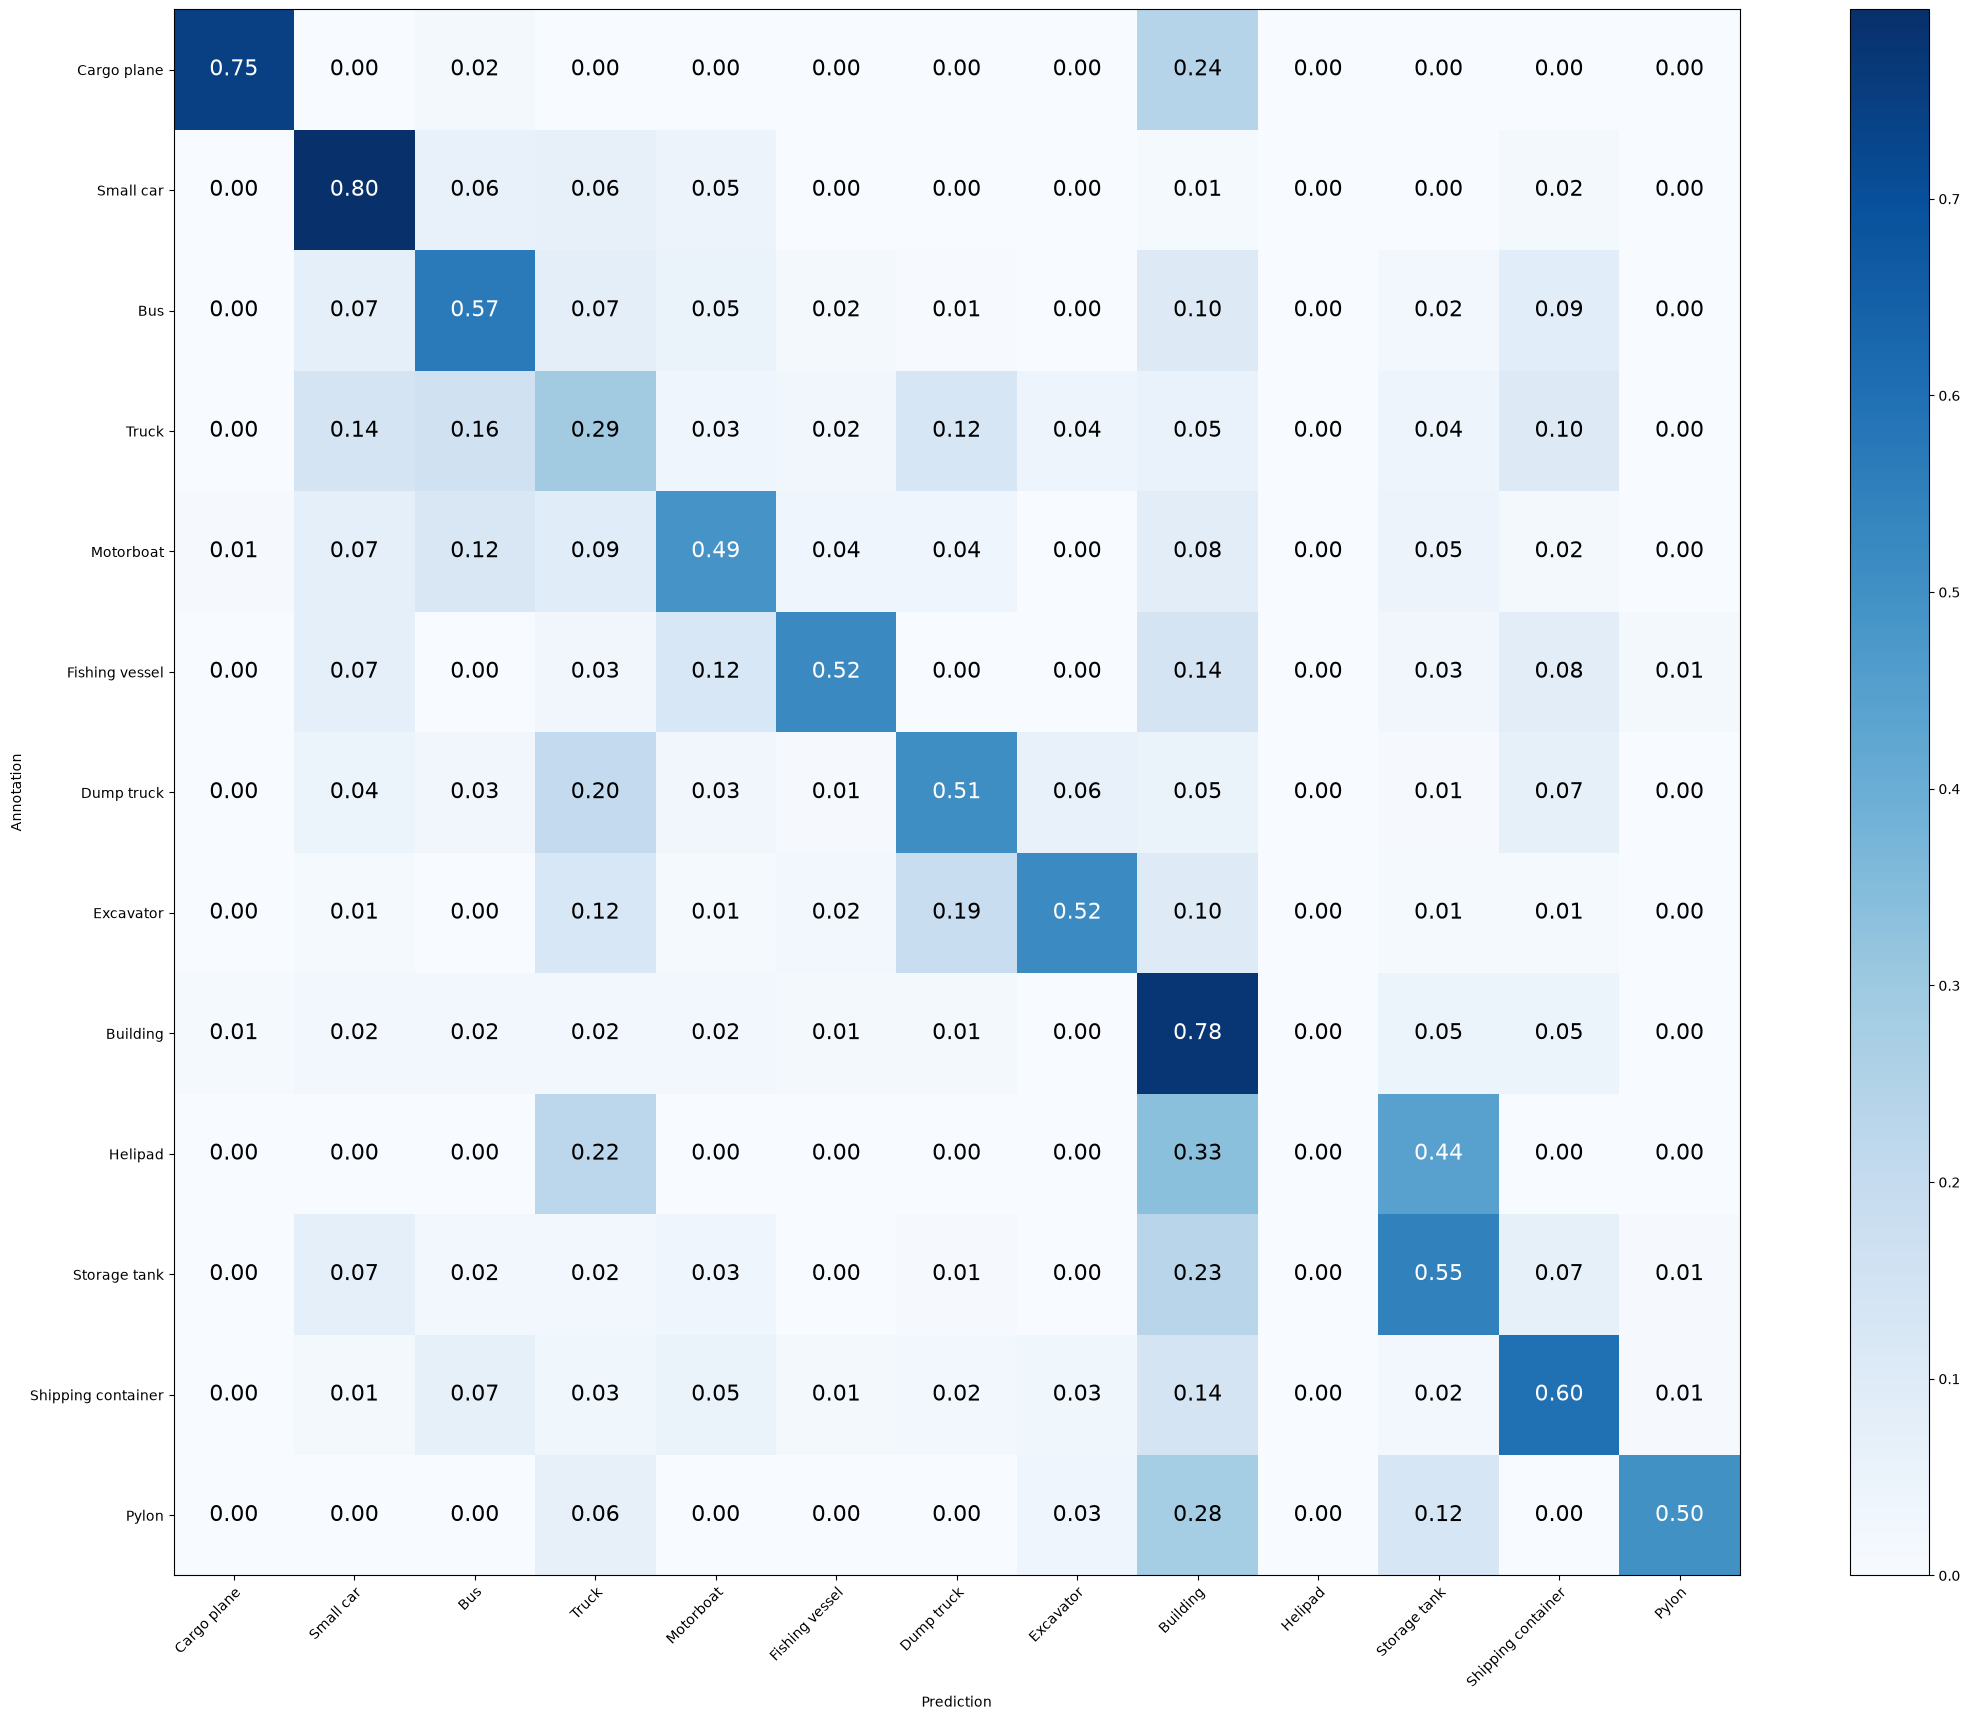

In [18]:
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(categories.values()))
draw_confusion_matrix(cm, categories)

In [19]:
import numpy as np

# Compute the accuracy
correct_samples_class = np.diag(cm).astype(float)
total_samples_class = np.sum(cm, axis=1).astype(float)
total_predicts_class = np.sum(cm, axis=0).astype(float)
print('Mean Accuracy: %.3f%%' % (np.sum(correct_samples_class) / np.sum(total_samples_class) * 100))
acc = correct_samples_class / np.maximum(total_samples_class, np.finfo(np.float64).eps)
print('Mean Recall: %.3f%%' % (acc.mean() * 100))
acc = correct_samples_class / np.maximum(total_predicts_class, np.finfo(np.float64).eps)
print('Mean Precision: %.3f%%' % (acc.mean() * 100))
for idx in range(len(categories)):
    # True/False Positives (TP/FP) refer to the number of predicted positives that were correct/incorrect.
    # True/False Negatives (TN/FN) refer to the number of predicted negatives that were correct/incorrect.
    tp = cm[idx, idx]
    fp = sum(cm[:, idx]) - tp
    fn = sum(cm[idx, :]) - tp
    tn = sum(np.delete(sum(cm) - cm[idx, :], idx))
    # True Positive Rate: proportion of real positive cases that were correctly predicted as positive.
    recall = tp / np.maximum(tp+fn, np.finfo(np.float64).eps)
    # Precision: proportion of predicted positive cases that were truly real positives.
    precision = tp / np.maximum(tp+fp, np.finfo(np.float64).eps)
    # True Negative Rate: proportion of real negative cases that were correctly predicted as negative.
    specificity = tn / np.maximum(tn+fp, np.finfo(np.float64).eps)
    # Dice coefficient refers to two times the intersection of two sets divided by the sum of their areas.
    # Dice = 2 |A∩B| / (|A|+|B|) = 2 TP / (2 TP + FP + FN)
    f1_score = 2 * ((precision * recall) / np.maximum(precision+recall, np.finfo(np.float64).eps))
    print('> %s: Recall: %.3f%% Precision: %.3f%% Specificity: %.3f%% Dice: %.3f%%' % (list(categories.values())[idx], recall*100, precision*100, specificity*100, f1_score*100))

Mean Accuracy: 60.213%
Mean Recall: 52.724%
Mean Precision: 56.826%
> Cargo plane: Recall: 74.576% Precision: 89.796% Specificity: 99.725% Dice: 81.481%
> Small car: Recall: 79.635% Precision: 75.504% Specificity: 94.502% Dice: 77.515%
> Bus: Recall: 56.897% Precision: 51.295% Specificity: 94.474% Dice: 53.951%
> Truck: Recall: 28.631% Precision: 40.828% Specificity: 93.880% Dice: 33.659%
> Motorboat: Recall: 48.624% Precision: 45.299% Specificity: 96.376% Dice: 46.903%
> Fishing vessel: Recall: 52.055% Precision: 62.295% Specificity: 98.724% Dice: 56.716%
> Dump truck: Recall: 50.847% Precision: 50.000% Specificity: 96.585% Dice: 50.420%
> Excavator: Recall: 51.852% Precision: 64.615% Specificity: 98.718% Dice: 57.534%
> Building: Recall: 77.686% Precision: 65.581% Specificity: 90.212% Dice: 71.122%
> Helipad: Recall: 0.000% Precision: 0.000% Specificity: 100.000% Dice: 0.000%
> Storage tank: Recall: 54.605% Precision: 61.940% Specificity: 97.040% Dice: 58.042%
> Shipping container: R

#### Testing
Try to improve the results provided in the competition.

In [20]:
import os
import numpy as np

anns = []
for (dirpath, dirnames, filenames) in os.walk('../PROJECT/xview_recognition/xview_test'):
    for filename in filenames:
        if not filename.lower().endswith((".tif", ".tiff")):
            continue
        image = GenericImage(dirpath[29:] + '/' + filename)
        image.tile = np.array([0, 0, 224, 224])
        obj = GenericObject()
        obj.bb = (0, 0, 224, 224)
        obj.category = dirpath[dirpath.rfind('/')+1:]
        image.add_object(obj)
        anns.append(image)
print('Number of testing images: ' + str(len(anns)))

Number of testing images: 2365


In [21]:
# CAMBIO: Aplicar al test la misma reducción y normalización; cargar una vez y predecir por lotes.
# Código original conservado como comentarios:
# import numpy as np
#
# model.load_weights('model.keras')
# predictions_data = {"images": {}, "annotations": {}}
# for idx, ann in enumerate(anns):
#     image_data = {"image_id": ann.filename.split('/')[-1], "filename": ann.filename, "width": int(ann.tile[2]), "height": int(ann.tile[3])}
#     predictions_data["images"][idx] = image_data
#     # Load image
#     image = load_geoimage(ann.filename)
#     for obj_pred in ann.objects:
#         # Generate prediction
#         warped_image = np.expand_dims(image, 0)
#         predictions = model.predict(warped_image, verbose=0)
#         # Save prediction
#         pred_category = list(categories.values())[np.argmax(predictions)]
#         pred_score = np.max(predictions)
#         annotation_data = {"image_id": ann.filename.split('/')[-1], "category_id": pred_category, "bbox": [int(x) for x in obj_pred.bb]}
#         predictions_data["annotations"][idx] = annotation_data

# Código actualizado:
import numpy as np

model.load_weights(str(MODEL_PATH))
predictions_data = {"images": {}, "annotations": {}}
x_test = np.empty((len(anns), *IMAGE_SIZE, IMAGE_CHANNELS), dtype=np.float32)
for idx, ann in enumerate(anns):
    x_test[idx] = load_geoimage(ann.filename)
test_predictions = model.predict(x_test, batch_size=batch_size, verbose=0)

for idx, ann in enumerate(anns):
    # Los metadatos y bbox conservan las dimensiones originales del archivo.
    # Solo la entrada de la red se reduce a 32 × 32.
    image_data = {"image_id": ann.filename.split('/')[-1], "filename": ann.filename, "width": int(ann.tile[2]), "height": int(ann.tile[3])}
    predictions_data["images"][idx] = image_data
    for obj_pred in ann.objects:
        predictions = test_predictions[idx]
        pred_category = category_names[np.argmax(predictions)]
        pred_score = np.max(predictions)
        annotation_data = {"image_id": ann.filename.split('/')[-1], "category_id": pred_category, "bbox": [int(x) for x in obj_pred.bb]}
        predictions_data["annotations"][idx] = annotation_data


In [22]:
with open(PREDICTION_PATH, "w") as outfile:
    json.dump(predictions_data, outfile)